<a href="https://colab.research.google.com/github/peter-adepoju/math-neuro-ml/blob/main/week3/lesson10/Lesson10_Teaching_Notebook.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **MAMBA: Mathematical Sciences for Brain Data**
## Lesson 10 — The Chain Rule and Backpropagation: How a Change Travels Through a Network

**Course:** MAMBA: Mathematical Sciences for Brain Data\
**Week:** Week 3 — Calculus I\
**Lesson:** Lesson 10\
**Notebook type:** Teaching notebook

> *"A nudge to one weight changes a sum, which changes an activation, which changes the output, which changes the error. The chain rule multiplies those changes; backpropagation does it for every weight at once."*

---

### Functions inside functions

Lesson 9 differentiated single functions. Almost everything interesting is a **composition**. A firing rate depends on a membrane potential, which depends on a synaptic current, which depends on synaptic weights. A network's error depends on its output, which depends on the last layer, which depends on the layer before. The **chain rule** says how a small change at the start propagates to the end: multiply the local rates of change along the chain.

**Backpropagation** is the chain rule organised for a whole network. One pass forward computes the output, and one pass backward computes the derivative of the error with respect to **every** weight, at roughly the cost of a second forward pass. It is how essentially all modern neural networks learn, and it is the most important application of calculus in machine learning. This lesson builds it from scratch in NumPy: computation graphs, reverse accumulation, the derivatives of affine maps and activations, gradient checking, and the vanishing and exploding gradients that make deep networks hard to train. The mini-lab trains a small network to decode hand velocity from 170 motor-cortex neurons, using only code written here.

### Import Dependencies

In [1]:
# SETUP CELL
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots

RNG = np.random.default_rng(42)

# The same colourblind-conscious palette and markers as Lessons 1-9.
PALETTE = ['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#56B4E9']
MARKERS = ['o', 's', '^', 'D', 'v', 'P']

print("Setup complete.")

Setup complete.


### Interactive and animated plotting tools

As before, each static figure is followed by a **Plotly version** that you can zoom, pan, hover over, and save. Several have sliders: drag them, or press **Play**.

In [2]:
# INTERACTIVE/ANIMATION SETUP
import sys
import plotly.io as pio

if 'google.colab' not in sys.modules:
    pio.renderers.default = 'notebook_connected'
pio.templates['plotly_white'].layout.xaxis.showgrid = False
pio.templates['plotly_white'].layout.yaxis.showgrid = False

PLOTLY_CONFIG = {'displaylogo': False, 'responsive': True, 'scrollZoom': True,
                 'toImageButtonOptions': {'format': 'png', 'scale': 2}}

def play_pause_and_slider(labels, prefix, duration=150):
    # Play/Pause buttons and a frame slider, as used in Lessons 1-9.
    buttons = [dict(
        type='buttons', showactive=False, x=0.0, y=-0.12, xanchor='left', yanchor='top',
        buttons=[
            dict(label='Play', method='animate', args=[None, {'frame': {'duration': duration, 'redraw': True}, 'transition': {'duration': 0}, 'fromcurrent': True}]),
            dict(label='Pause', method='animate', args=[[None], {'frame': {'duration': 0, 'redraw': False}, 'mode': 'immediate'}]),
        ],
    )]
    sliders = [dict(
        active=0, currentvalue={'prefix': prefix}, pad={'t': 50},
        steps=[dict(label=str(lab), method='animate', args=[[str(k)], {'mode': 'immediate', 'frame': {'duration': 0, 'redraw': True}, 'transition': {'duration': 0}}])
               for k, lab in enumerate(labels)],
    )]
    return buttons, sliders

def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def central_diff(f, x, h=1e-5):
    return (f(x + h) - f(x - h)) / (2 * h)

print('Interactive plotting and animation tools are ready.')

Interactive plotting and animation tools are ready.


# **Motivation: nudging a synaptic weight**

A model neuron receives an input $x$ (say, a stimulus feature) through a synapse of weight $w$, adds a bias $b$, and fires at a rate given by a sigmoid of its total drive:

$$z = wx + b, \qquad r = r_{\max}\,\sigma(z).$$

If plasticity strengthens the synapse by a tiny amount $\Delta w$, how much does the firing rate change? The change has to travel along a chain: $w \to z \to r$. A change $\Delta w$ changes the drive by $\Delta z \approx \frac{\partial z}{\partial w}\Delta w = x\,\Delta w$, and that changes the rate by $\Delta r \approx \frac{dr}{dz}\Delta z = r_{\max}\sigma'(z)\,\Delta z$. Putting the two links together:

$$\frac{dr}{dw} = \frac{dr}{dz}\cdot\frac{dz}{dw} = r_{\max}\,\sigma'(z)\cdot x .$$

w = 0.5: drive z = -2.0, rate   6.0 spikes/s;  chain rule dr/dw = 10.499, central difference 10.499  (spikes/s per unit weight)
w = 1.5: drive z =  0.0, rate  25.0 spikes/s;  chain rule dr/dw = 25.000, central difference 25.000  (spikes/s per unit weight)
w = 3.0: drive z =  3.0, rate  47.6 spikes/s;  chain rule dr/dw =  4.518, central difference  4.518  (spikes/s per unit weight)


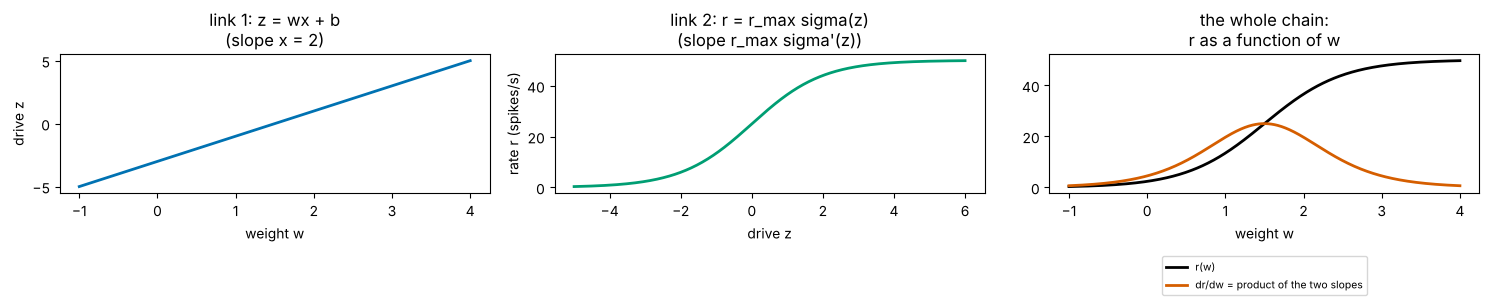

In [3]:
r_max, x_in, b0 = 50.0, 2.0, -3.0                                 # spikes/s; input (a.u.); bias
def rate_of_w(w):
    return r_max * sigmoid(w * x_in + b0)

for w0 in [0.5, 1.5, 3.0]:
    z0 = w0 * x_in + b0
    chain = r_max * sigmoid(z0) * (1 - sigmoid(z0)) * x_in        # dr/dz * dz/dw
    print(f"w = {w0}: drive z = {z0:4.1f}, rate {rate_of_w(w0):5.1f} spikes/s;  chain rule dr/dw = {chain:6.3f}, central difference {central_diff(rate_of_w, w0):6.3f}  (spikes/s per unit weight)")

ws = np.linspace(-1, 4, 501)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].plot(ws, ws * x_in + b0, color=PALETTE[0], lw=2); axes[0].set_title('link 1: z = wx + b\n(slope x = 2)')
axes[0].set_xlabel('weight w'); axes[0].set_ylabel('drive z')
zs = np.linspace(-5, 6, 501)
axes[1].plot(zs, r_max * sigmoid(zs), color=PALETTE[2], lw=2); axes[1].set_title("link 2: r = r_max sigma(z)\n(slope r_max sigma'(z))")
axes[1].set_xlabel('drive z'); axes[1].set_ylabel('rate r (spikes/s)')
axes[2].plot(ws, rate_of_w(ws), color='black', lw=2, label='r(w)')
axes[2].plot(ws, r_max * sigmoid(ws * x_in + b0) * (1 - sigmoid(ws * x_in + b0)) * x_in, color=PALETTE[1], lw=2, label='dr/dw = product of the two slopes')
axes[2].set_xlabel('weight w'); axes[2].set_title('the whole chain:\nr as a function of w'); axes[2].legend(fontsize=7.5, loc='upper center', bbox_to_anchor=(0.5, -0.42))
plt.tight_layout(); plt.show()

The sensitivity of the rate to the weight is large only where **both** links are steep: the sigmoid must be in its sensitive middle range. With $w = 3$ the neuron is near saturation and plasticity at this synapse barely changes its output. This is the whole lesson in miniature: derivatives multiply along chains, and a single flat link stalls the whole chain.

# **Part 1: The Chain Rule**

If $y = f(u)$ and $u = g(x)$, so that $y = f(g(x))$, then

$$\frac{dy}{dx} = \frac{dy}{du}\cdot\frac{du}{dx} = f'\big(g(x)\big)\,g'(x).$$

In words: **outer derivative evaluated at the inner value, times inner derivative**. The Leibniz notation makes it look like fractions cancelling, and the **units** do cancel: (spikes/s per mV) × (mV per nA) = spikes/s per nA.

**Why it is true, in one line of linear approximation (Lesson 9).** A small change $\Delta x$ changes $u$ by $\Delta u \approx g'(x)\Delta x$, and that changes $y$ by $\Delta y \approx f'(u)\Delta u \approx f'(u)\,g'(x)\,\Delta x$. Each link scales the nudge by its local slope.

**Longer chains** multiply more factors: for $y = f(g(h(x)))$,

$$\frac{dy}{dx} = f'(g(h(x)))\cdot g'(h(x))\cdot h'(x).$$

Each factor is a **local derivative**: it depends only on one link and on the value flowing through it.

| Function | Inner $u$ | Derivative |
|---|---|---|
| $e^{-t/\tau}$ | $u = -t/\tau$ | $-\frac{1}{\tau}e^{-t/\tau}$ |
| $\sin(\omega t)$ | $u = \omega t$ | $\omega\cos(\omega t)$ |
| $\sigma(wx + b)$ (in $x$) | $u = wx + b$ | $w\,\sigma(u)(1 - \sigma(u))$ |
| $\ln(1 + e^{x})$ (softplus) | $u = 1 + e^{x}$ | $\frac{e^x}{1 + e^x} = \sigma(x)$ |
| $e^{-(x - \mu)^2/2s^2}$ (Gaussian tuning) | $u = -(x - \mu)^2/2s^2$ | $-\frac{x - \mu}{s^2}e^{u}$ |
| $(1 + x^2)^{1/2}$ | $u = 1 + x^2$ | $\frac{x}{\sqrt{1 + x^2}}$ |

In [4]:
tests = [
    ('exp(-t/tau), tau = 20',      lambda t: np.exp(-t / 20),               lambda t: -np.exp(-t / 20) / 20),
    ('sin(2 pi 8 t)',              lambda t: np.sin(2 * np.pi * 8 * t),     lambda t: 2 * np.pi * 8 * np.cos(2 * np.pi * 8 * t)),
    ('sigma(3x - 1)',              lambda x: sigmoid(3 * x - 1),            lambda x: 3 * sigmoid(3 * x - 1) * (1 - sigmoid(3 * x - 1))),
    ('Gaussian tuning, mu=1, s=.5', lambda x: np.exp(-(x - 1)**2 / 0.5),    lambda x: -(x - 1) / 0.25 * np.exp(-(x - 1)**2 / 0.5)),
    ('sqrt(1 + x^2)',              lambda x: np.sqrt(1 + x**2),             lambda x: x / np.sqrt(1 + x**2)),
    ('three links: exp(sin(x^2))', lambda x: np.exp(np.sin(x**2)),          lambda x: np.exp(np.sin(x**2)) * np.cos(x**2) * 2 * x),
]
xt = np.array([0.1, 0.4, 0.9, 1.7])
for name, f, df in tests:
    num = central_diff(f, xt)
    print(f"{name:<30} max relative difference, chain rule vs central difference: {np.max(np.abs(df(xt) - num) / np.maximum(np.abs(num), 1e-12)):.1e}")

exp(-t/tau), tau = 20          max relative difference, chain rule vs central difference: 5.7e-11
sin(2 pi 8 t)                  max relative difference, chain rule vs central difference: 4.2e-08
sigma(3x - 1)                  max relative difference, chain rule vs central difference: 1.6e-10
Gaussian tuning, mu=1, s=.5    max relative difference, chain rule vs central difference: 2.1e-10
sqrt(1 + x^2)                  max relative difference, chain rule vs central difference: 5.2e-11
three links: exp(sin(x^2))     max relative difference, chain rule vs central difference: 2.3e-10


#### Animation: a nudge travelling down a chain

Take the three-link chain $x \to u = x^2 \to v = \sin u \to y = e^{v}$. The animation applies a nudge $\Delta x = 0.05$ at different starting points. Each bar shows how big the nudge has become after each link: multiplied by $2x$, then by $\cos u$, then by $e^{v}$. Where $\cos u \approx 0$ the nudge is extinguished in the middle of the chain, whatever the other links do.

In [5]:
x_points = np.round(np.linspace(0.2, 2.4, 12), 2)
def nudges(x0, dx=0.05):
    u0, v0 = x0**2, np.sin(x0**2)
    du = 2 * x0 * dx; dv = np.cos(u0) * du; dy = np.exp(v0) * dv
    return [dx, du, dv, dy], [2 * x0, np.cos(u0), np.exp(v0)]
labels_n = ['Δx', 'Δu = 2x·Δx', 'Δv = cos(u)·Δu', 'Δy = e^v·Δv']
vals0, _ = nudges(x_points[0])
fig_nudge = go.Figure(go.Bar(x=labels_n, y=vals0, marker_color=[PALETTE[0], PALETTE[2], PALETTE[3], PALETTE[1]]))
fig_nudge.frames = [go.Frame(name=str(k), data=[go.Bar(y=nudges(x0)[0])],
                             layout=go.Layout(title=f'x = {x0}: local slopes 2x = {nudges(x0)[1][0]:.2f}, cos u = {nudges(x0)[1][1]:.2f}, e^v = {nudges(x0)[1][2]:.2f};  dy/dx = {nudges(x0)[0][3] / 0.05:.2f}'))
                    for k, x0 in enumerate(x_points)]
buttons, sliders = play_pause_and_slider(list(x_points), prefix='starting point x = ', duration=700)
fig_nudge.update_layout(title=fig_nudge.frames[0].layout.title.text, yaxis=dict(range=[-0.35, 0.35], title='size of the nudge'), template='plotly_white',
                        width=850, height=470, updatemenus=buttons, sliders=sliders)
fig_nudge.show(config=PLOTLY_CONFIG)

# **Part 2: Computation Graphs, the Forward Pass and Reverse Accumulation**

Any formula can be drawn as a **computation graph**: nodes are elementary operations (add, multiply, exp, sigmoid, square), and edges carry values from inputs to the output. Take the loss of the motivating neuron on one training example with target rate $y$:

$$z = wx + b,\qquad r = r_{\max}\sigma(z),\qquad L = \tfrac12(r - y)^2 .$$

**Forward pass.** Evaluate the graph from inputs to output, and **store every intermediate value** ($z$, $\sigma(z)$, $r$).

**Backward pass (reverse accumulation).** Start at the output with $\frac{\partial L}{\partial L} = 1$. Walk the graph backwards. At each node, multiply the derivative arriving from above (the "upstream gradient") by the node's **local derivative**, and pass the result down:

$$\frac{\partial L}{\partial r} = r - y,\quad \frac{\partial L}{\partial z} = \frac{\partial L}{\partial r}\cdot r_{\max}\sigma'(z),\quad \frac{\partial L}{\partial w} = \frac{\partial L}{\partial z}\cdot x,\quad \frac{\partial L}{\partial b} = \frac{\partial L}{\partial z}\cdot 1 .$$

Notice that $\frac{\partial L}{\partial z}$ is computed **once** and reused for both $w$ and $b$. That reuse is what makes backpropagation efficient.

**Several inputs.** $L$ depends on $w$ and $b$ (and $x$): a function of several variables. $\frac{\partial L}{\partial w}$, a **partial derivative**, is the derivative with respect to $w$ while everything else is held fixed (Lesson 14 develops this properly). If a value feeds into **several** later nodes (it "fans out"), its gradient is the **sum** of the gradients arriving along each path.

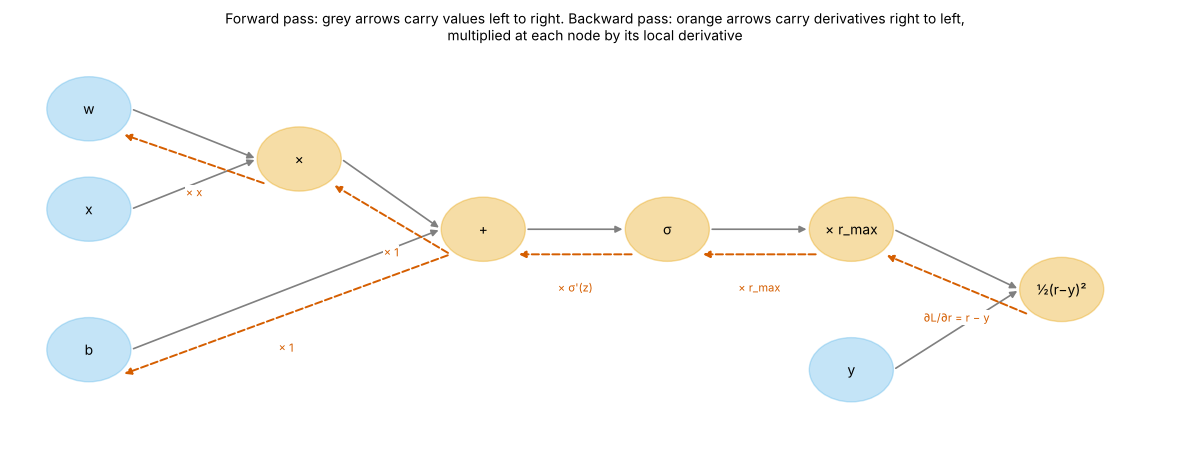

In [6]:
def draw_graph(ax):
    nodes = {'x': (0, 2), 'w': (0, 3), 'b': (0, 0.6), 'mul': (1.6, 2.5), 'add': (3.0, 1.8), 'sigma': (4.4, 1.8), 'r': (5.8, 1.8),
             'y': (5.8, 0.4), 'L': (7.4, 1.2)}
    labels = {'x': 'x', 'w': 'w', 'b': 'b', 'mul': '×', 'add': '+', 'sigma': 'σ', 'r': '× r_max', 'y': 'y', 'L': '½(r−y)²'}
    edges = [('x', 'mul'), ('w', 'mul'), ('mul', 'add'), ('b', 'add'), ('add', 'sigma'), ('sigma', 'r'), ('r', 'L'), ('y', 'L')]
    for a, c in edges:
        (x0, y0), (x1, y1) = nodes[a], nodes[c]
        ax.annotate('', xy=(x1 - 0.32, y1), xytext=(x0 + 0.32, y0), arrowprops=dict(arrowstyle='-|>', color='grey', lw=1.2))
    for k, (xx, yy) in nodes.items():
        leaf = k in ('x', 'w', 'b', 'y')
        ax.add_patch(plt.Circle((xx, yy), 0.32, color=PALETTE[5] if leaf else PALETTE[4], alpha=0.35))
        ax.text(xx, yy, labels[k], ha='center', va='center', fontsize=10)
    back = [('L', 'r', '∂L/∂r = r − y'), ('r', 'sigma', '× r_max'), ('sigma', 'add', "× σ'(z)"), ('add', 'mul', '× 1'), ('add', 'b', '× 1'), ('mul', 'w', '× x')]
    for a, c, lab in back:
        (x0, y0), (x1, y1) = nodes[a], nodes[c]
        ax.annotate('', xy=(x1 + 0.25, y1 - 0.25), xytext=(x0 - 0.25, y0 - 0.25), arrowprops=dict(arrowstyle='-|>', color=PALETTE[1], lw=1.4, ls='--'))
        ax.text((x0 + x1) / 2, (y0 + y1) / 2 - 0.62, lab, color=PALETTE[1], fontsize=8, ha='center', bbox=dict(fc='white', ec='none', pad=0.5))
    ax.set_xlim(-0.6, 8.3); ax.set_ylim(-0.3, 3.6); ax.axis('off')
    ax.set_title('Forward pass: grey arrows carry values left to right. Backward pass: orange arrows carry derivatives right to left,\n'
                 'multiplied at each node by its local derivative', fontsize=10)
fig, ax = plt.subplots(figsize=(12, 4.6))
draw_graph(ax)
plt.tight_layout(); plt.show()

In [7]:
# Forward and backward pass for one example, by hand.
w, b, x, y_target = 1.2, -1.0, 2.0, 30.0
z = w * x + b                    # forward: store every intermediate value
s = sigmoid(z)
r = r_max * s
L = 0.5 * (r - y_target)**2
dL_dr = r - y_target             # backward: start at the loss
dL_dz = dL_dr * r_max * s * (1 - s)
dL_dw = dL_dz * x
dL_db = dL_dz * 1.0
print(f"forward : z = {z:.3f}, sigma = {s:.4f}, r = {r:.3f} spikes/s, L = {L:.3f}")
print(f"backward: dL/dr = {dL_dr:.3f}, dL/dz = {dL_dz:.3f}, dL/dw = {dL_dw:.3f}, dL/db = {dL_db:.3f}")

loss_w = lambda ww: 0.5 * (r_max * sigmoid(ww * x + b) - y_target)**2
loss_b = lambda bb: 0.5 * (r_max * sigmoid(w * x + bb) - y_target)**2
print(f"check   : central differences dL/dw = {central_diff(loss_w, w):.3f}, dL/db = {central_diff(loss_b, b):.3f}")

forward : z = 1.400, sigma = 0.8022, r = 40.109 spikes/s, L = 51.098
backward: dL/dr = 10.109, dL/dz = 80.209, dL/dw = 160.418, dL/db = 80.209
check   : central differences dL/dw = 160.418, dL/db = 80.209


### A tiny automatic-differentiation engine

Deep-learning libraries (PyTorch, JAX, TensorFlow) automate exactly this. Every operation records its inputs and its local derivative; calling `backward()` walks the graph in reverse order and accumulates gradients. The class below does it for scalars in about 40 lines. It is written for this course in the spirit of Andrej Karpathy's *micrograd* (MIT licence). Note the `+=` in every backward rule: that is the "sum over paths" for values used more than once.

In [8]:
class Value:
    # A scalar that remembers how it was computed, so that gradients can flow back through it.
    def __init__(self, data, parents=(), op=''):
        self.data, self.grad = float(data), 0.0
        self._parents, self._op = parents, op
        self._backward = lambda: None

    def __add__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data + other.data, (self, other), '+')
        def _backward():
            self.grad += out.grad                 # local derivative of a + b with respect to a is 1
            other.grad += out.grad
        out._backward = _backward
        return out

    def __mul__(self, other):
        other = other if isinstance(other, Value) else Value(other)
        out = Value(self.data * other.data, (self, other), '*')
        def _backward():
            self.grad += other.data * out.grad    # d(ab)/da = b
            other.grad += self.data * out.grad
        out._backward = _backward
        return out

    def __sub__(self, other):
        return self + (other * -1.0)

    def __pow__(self, k):
        out = Value(self.data**k, (self,), f'**{k}')
        def _backward():
            self.grad += k * self.data**(k - 1) * out.grad
        out._backward = _backward
        return out

    def sigmoid(self):
        sv = 1 / (1 + np.exp(-self.data))
        out = Value(sv, (self,), 'sigmoid')
        def _backward():
            self.grad += sv * (1 - sv) * out.grad
        out._backward = _backward
        return out

    def backward(self):
        # Order the graph so that every node comes after its parents, then run the local rules in reverse.
        order, seen = [], set()
        def visit(v):
            if id(v) not in seen:
                seen.add(id(v))
                for p in v._parents:
                    visit(p)
                order.append(v)
        visit(self)
        self.grad = 1.0
        for v in reversed(order):
            v._backward()

w_v, b_v, x_v = Value(1.2), Value(-1.0), Value(2.0)
r_v = (w_v * x_v + b_v).sigmoid() * r_max
L_v = (r_v - y_target)**2 * 0.5
L_v.backward()
print(f"autodiff: L = {L_v.data:.3f}, dL/dw = {w_v.grad:.3f}, dL/db = {b_v.grad:.3f}, dL/dx = {x_v.grad:.3f}")

# Fan-out: a value used twice receives the SUM of the gradients along both paths.
a = Value(3.0)
f_v = a * a + a * 2.0                     # f = a^2 + 2a, df/da = 2a + 2 = 8
f_v.backward()
print(f"fan-out : f = a^2 + 2a at a = 3: df/da = {a.grad}  (expected 8)")

autodiff: L = 51.098, dL/dw = 160.418, dL/db = 80.209, dL/dx = 96.251
fan-out : f = a^2 + 2a at a = 3: df/da = 8.0  (expected 8)


### Why reverse mode? Counting the cost

A network with $P$ parameters needs $P$ partial derivatives of one loss. Finite differences need one extra forward pass **per parameter**: cost about $P$ forward passes. Reverse accumulation gets all $P$ derivatives from **one** backward pass, costing roughly as much as one forward pass, because each local derivative is used once and every shared upstream gradient is computed once. For a network with millions of weights, this is the difference between impossible and routine.

In [9]:
import time
def small_net_loss(params, X, Y, H):
    N = X.shape[1]
    W1 = params[:H * N].reshape(H, N); W2 = params[H * N:].reshape(1, H)
    return 0.5 * np.mean((np.tanh(X @ W1.T) @ W2.T - Y)**2)
def small_net_grad(params, X, Y, H):
    N = X.shape[1]
    W1 = params[:H * N].reshape(H, N); W2 = params[H * N:].reshape(1, H)
    A1 = np.tanh(X @ W1.T); P = A1 @ W2.T
    dP = (P - Y) / len(Y)
    dW2 = dP.T @ A1
    dW1 = ((dP @ W2) * (1 - A1**2)).T @ X
    return np.concatenate([dW1.ravel(), dW2.ravel()])

Xs, Ys = RNG.normal(size=(200, 20)), RNG.normal(size=(200, 1))
print(f"{'parameters':>10} {'finite differences (s)':>24} {'backprop (s)':>14}")
for H in [5, 20, 80]:
    params = RNG.normal(0, 0.3, H * 20 + H)
    t0 = time.perf_counter()
    fd = np.array([(small_net_loss(params + e, Xs, Ys, H) - small_net_loss(params - e, Xs, Ys, H)) / 2e-5
                   for e in np.eye(params.size) * 1e-5])
    t_fd = time.perf_counter() - t0
    t0 = time.perf_counter(); bp = small_net_grad(params, Xs, Ys, H); t_bp = time.perf_counter() - t0
    print(f"{params.size:>10} {t_fd:>24.4f} {t_bp:>14.5f}   (max difference {np.max(np.abs(fd - bp)):.1e})")

parameters   finite differences (s)   backprop (s)
       105                   0.0061        0.00007   (max difference 8.1e-12)
       420                   0.0279        0.00010   (max difference 1.7e-11)


      1680                   0.2574        0.00022   (max difference 4.9e-11)


# **Part 3: Backpropagation Through Layers — Affine Maps and Activations**

A layer of a network (Lessons 2 and 4) computes an affine map followed by an elementwise activation:

$$\mathbf{z} = \mathbf{W}\mathbf{a}_{\text{in}} + \mathbf{b}, \qquad \mathbf{a}_{\text{out}} = \phi(\mathbf{z}),$$

with $\mathbf{W}$ of shape $(n_{\text{out}}, n_{\text{in}})$. Write $\boldsymbol\delta = \partial L/\partial\mathbf{z}$ for the upstream gradient arriving at $\mathbf{z}$ (a vector, one entry per unit). The chain rule, applied entry by entry, gives three rules that are worth memorising:

| Gradient | Formula | Shape | Why |
|---|---|---|---|
| weights | $\dfrac{\partial L}{\partial\mathbf{W}} = \boldsymbol\delta\,\mathbf{a}_{\text{in}}^{\mathsf T}$ | $(n_{\text{out}}, n_{\text{in}})$ | $z_i = \sum_j W_{ij}a_j + b_i$, so $\partial z_i/\partial W_{ij} = a_j$: an **outer product** (Lesson 4) |
| bias | $\dfrac{\partial L}{\partial\mathbf{b}} = \boldsymbol\delta$ | $(n_{\text{out}},)$ | $\partial z_i/\partial b_i = 1$ |
| input | $\dfrac{\partial L}{\partial\mathbf{a}_{\text{in}}} = \mathbf{W}^{\mathsf T}\boldsymbol\delta$ | $(n_{\text{in}},)$ | $a_j$ feeds every $z_i$ (fan-out): sum over $i$ of $W_{ij}\delta_i$ |

and through the activation, elementwise (each unit's output depends only on its own input):

$$\frac{\partial L}{\partial\mathbf{z}} = \frac{\partial L}{\partial\mathbf{a}_{\text{out}}} \odot \phi'(\mathbf{z}).$$

So **the backward pass runs each weight matrix backwards, as its transpose**, and scales by the activation slopes. With a batch of $n$ examples stored as rows (Lesson 3), $\boldsymbol\delta$ becomes a matrix $\boldsymbol\Delta$ of shape $(n, n_{\text{out}})$, and the gradients sum over the batch: $\partial L/\partial\mathbf{W} = \boldsymbol\Delta^{\mathsf T}\mathbf{A}_{\text{in}}$, $\partial L/\partial\mathbf{b} = $ column sums of $\boldsymbol\Delta$, $\partial L/\partial\mathbf{A}_{\text{in}} = \boldsymbol\Delta\mathbf{W}$.

Hebb's rule ("cells that fire together wire together") has the same outer-product shape: the change of weight $W_{ij}$ is proportional to post-synaptic activity times pre-synaptic activity. In backpropagation the "post-synaptic" factor is the error signal $\delta_i$.

In [10]:
def layer_forward(A_in, W, b, act):
    Z = A_in @ W.T + b                                   # (n, n_out)
    if act == 'tanh':
        A_out = np.tanh(Z)
    elif act == 'relu':
        A_out = np.maximum(Z, 0)
    else:                                                # 'linear' (output layer)
        A_out = Z
    return Z, A_out

def act_slope(Z, A_out, act):
    if act == 'tanh':
        return 1 - A_out**2
    if act == 'relu':
        return (Z > 0).astype(float)
    return np.ones_like(Z)

def mlp_forward(params, X, acts):
    # params: list of (W, b); acts: one activation name per layer. Returns the list of (Z, A) per layer, input first.
    cache = [(None, X)]
    for (W, b), act in zip(params, acts):
        cache.append(layer_forward(cache[-1][1], W, b, act))
    return cache

def mlp_backward(params, cache, Y, acts):
    # Mean squared error L = (1/2n) sum ||prediction - Y||^2; returns [(dW, db), ...] and dL/dX.
    n = len(Y)
    dA = (cache[-1][1] - Y) / n                          # dL/d(prediction)
    grads = [None] * len(params)
    for k in range(len(params) - 1, -1, -1):
        Z, A_out = cache[k + 1]
        delta = dA * act_slope(Z, A_out, acts[k])        # through the activation (elementwise)
        A_in = cache[k][1]
        grads[k] = (delta.T @ A_in, delta.sum(axis=0))   # outer products summed over the batch; bias: column sums
        dA = delta @ params[k][0]                        # through the weights, backwards: W^T delta for each example
    return grads, dA

def mlp_loss(params, X, Y, acts):
    return 0.5 * np.mean(np.sum((mlp_forward(params, X, acts)[-1][1] - Y)**2, axis=1))

# Gradient check on a small random network: every single weight, by central differences.
sizes, acts_chk = [5, 4, 3, 2], ['tanh', 'relu', 'linear']
params_chk = [(RNG.normal(0, 0.7, (sizes[k + 1], sizes[k])), RNG.normal(0, 0.1, sizes[k + 1])) for k in range(3)]
Xc, Yc = RNG.normal(size=(10, 5)), RNG.normal(size=(10, 2))
grads_chk, _ = mlp_backward(params_chk, mlp_forward(params_chk, Xc, acts_chk), Yc, acts_chk)
worst = 0.0
for k, (W, b) in enumerate(params_chk):
    for M, G in [(W, grads_chk[k][0]), (b, grads_chk[k][1])]:
        for idx in np.ndindex(M.shape):
            old = M[idx]
            M[idx] = old + 1e-5; lp = mlp_loss(params_chk, Xc, Yc, acts_chk)
            M[idx] = old - 1e-5; lm = mlp_loss(params_chk, Xc, Yc, acts_chk)
            M[idx] = old
            num = (lp - lm) / 2e-5
            worst = max(worst, abs(num - G[idx]) / max(abs(num) + abs(G[idx]), 1e-12))
n_params = sum(W.size + b.size for W, b in params_chk)
print(f"gradient check over all {n_params} parameters: largest relative error {worst:.1e}")

gradient check over all 47 parameters: largest relative error 3.8e-09


A relative error around $10^{-9}$ or smaller means the backward pass is right; values above about $10^{-4}$ mean a bug (or a ReLU input sitting within $10^{-5}$ of its corner, where the central difference straddles the kink). **Always gradient-check hand-written backpropagation** on a small network before trusting it.

# **Part 4: Products of Derivatives — Vanishing and Exploding Gradients**

Backpropagation through $L$ layers multiplies $L$ factors: each layer contributes its weight matrix (transposed) and its activation slopes. For a single unit per layer with weight $w$ and slope $\phi'$, the gradient reaching the first layer is roughly

$$\frac{\partial L}{\partial a_1} \approx \prod_{k=1}^{L} w\,\phi'(z_k)\cdot\frac{\partial L}{\partial a_L}.$$

A product of many numbers is extreme. If every factor is $0.5$, ten layers give $0.5^{10} \approx 10^{-3}$; if every factor is $1.5$, they give $1.5^{10} \approx 58$. Gradients **vanish** (the early layers stop learning) or **explode** (learning becomes unstable). The sigmoid, with $\sigma' \le 1/4$, makes vanishing almost inevitable unless the weights are large, and large weights push units into saturation where $\sigma'$ is tiny. This is Lesson 6 again: repeated multiplication is governed by the size of the factors, and for matrices by their singular values and eigenvalues.

The remedies used in practice all aim to keep each factor close to 1:
- **activations** whose slope is 1 where active (ReLU);
- **initialisation** that scales random weights to preserve signal size: variance $1/n_{\text{in}}$ for tanh (Xavier/Glorot), $2/n_{\text{in}}$ for ReLU (He);
- **residual connections** ($\mathbf{a}_{k+1} = \mathbf{a}_k + f(\mathbf{a}_k)$, so each factor is "1 + something");
- **normalisation** layers, **gradient clipping**, and gated recurrent units (LSTMs) for recurrent networks.

The figures below measure the size of the **error signal** $\boldsymbol\delta_k = \partial L/\partial\mathbf{z}_k$ arriving at each layer of a random 12-layer network, relative to the last layer. (The weight gradient $\boldsymbol\delta_k\mathbf{a}_{k-1}^{\mathsf T}$ also contains the forward activations, which can shrink or grow in the opposite direction and partly mask the effect; $\boldsymbol\delta$ is the clean measure of what backpropagation delivers.)

sigmoid  (standard initialisation): error signal at the first layer / at the last layer = 1.0e-07
tanh     (standard initialisation): error signal at the first layer / at the last layer = 2.4e-01
relu     (standard initialisation): error signal at the first layer / at the last layer = 6.0e-01
ReLU, weights x 0.5: first / last = 2.9e-04
ReLU, weights x 0.7: first / last = 1.2e-02
ReLU, weights x 1.0: first / last = 6.0e-01
ReLU, weights x 1.4: first / last = 2.4e+01
ReLU, weights x 2.0: first / last = 1.2e+03


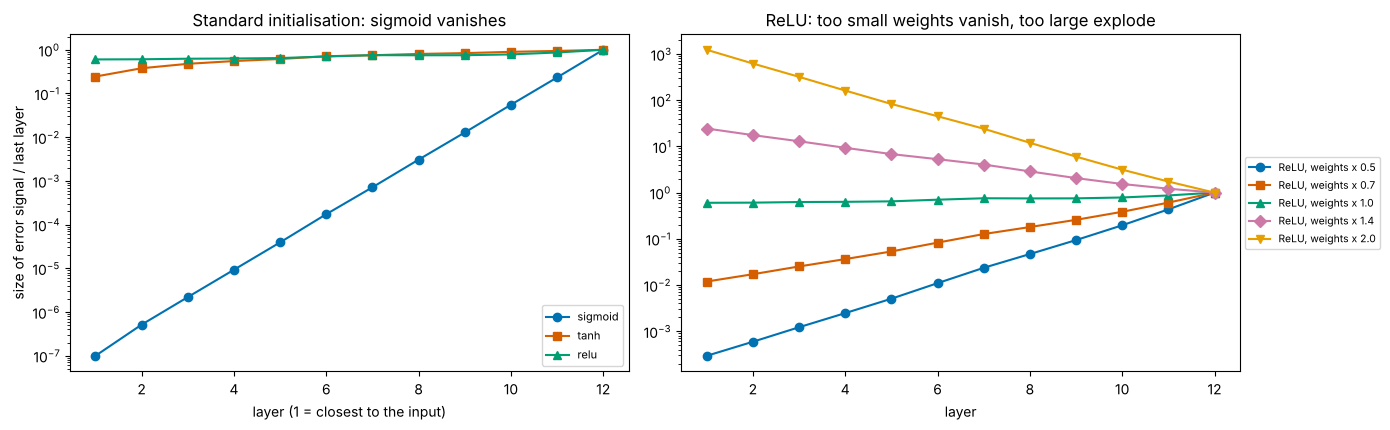

In [11]:
def layer_grad_norms(act, depth=12, width=64, weight_scale=1.0, n=500, seed=0):
    # Build a deep network with random weights (std = weight_scale * sqrt(gain / n_in)), backpropagate a random error
    # and return the size of the error signal delta = dL/dz arriving at each layer (first layer first).
    rng = np.random.default_rng(seed)
    gain = {'sigmoid': 1.0, 'tanh': 1.0, 'relu': 2.0}[act]
    f = {'sigmoid': sigmoid, 'tanh': np.tanh, 'relu': lambda z: np.maximum(z, 0)}[act]
    df = {'sigmoid': lambda a, z: a * (1 - a), 'tanh': lambda a, z: 1 - a**2, 'relu': lambda a, z: (z > 0) * 1.0}[act]
    A = [rng.normal(size=(n, width))]; Zs = [None]; Ws = []
    for _ in range(depth):
        W = rng.normal(0, weight_scale * np.sqrt(gain / width), (width, width)); Ws.append(W)
        Z = A[-1] @ W.T; Zs.append(Z); A.append(f(Z))
    dA = rng.normal(size=(n, width)) / n
    norms = []
    for k in range(depth, 0, -1):
        delta = dA * df(A[k], Zs[k])
        norms.append(np.linalg.norm(delta))
        dA = delta @ Ws[k - 1]
    return np.array(norms[::-1])

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
for act, colour, mk in zip(['sigmoid', 'tanh', 'relu'], PALETTE, MARKERS):
    g = layer_grad_norms(act)
    axes[0].semilogy(np.arange(1, 13), g / g[-1], marker=mk, color=colour, label=act)
    print(f"{act:<8} (standard initialisation): error signal at the first layer / at the last layer = {g[0] / g[-1]:.1e}")
axes[0].set_xlabel('layer (1 = closest to the input)'); axes[0].set_ylabel('size of error signal / last layer'); axes[0].set_title('Standard initialisation: sigmoid vanishes')
axes[0].legend(fontsize=8)
for scale, colour, mk in zip([0.5, 0.7, 1.0, 1.4, 2.0], PALETTE, MARKERS):
    g = layer_grad_norms('relu', weight_scale=scale)
    axes[1].semilogy(np.arange(1, 13), g / g[-1], marker=mk, color=colour, label=f'ReLU, weights x {scale}')
    print(f"ReLU, weights x {scale}: first / last = {g[0] / g[-1]:.1e}")
axes[1].set_xlabel('layer'); axes[1].set_title('ReLU: too small weights vanish, too large explode'); axes[1].legend(fontsize=7.5, loc='center left', bbox_to_anchor=(1.0, 0.5))
plt.tight_layout(); plt.show()

#### Interactive version: change the weight scale of a 12-layer ReLU network

In [12]:
scales = [0.5, 0.6, 0.7, 0.8, 0.9, 1.0, 1.2, 1.4, 1.6, 1.8, 2.0]
curves = {s_: layer_grad_norms('relu', weight_scale=s_) for s_ in scales}
fig_vg = go.Figure(go.Scatter(x=np.arange(1, 13), y=curves[scales[0]] / curves[scales[0]][-1], mode='lines+markers', line=dict(color=PALETTE[0], width=3)))
fig_vg.frames = [go.Frame(name=str(k), data=[go.Scatter(y=curves[s_] / curves[s_][-1])],
                          layout=go.Layout(title=f'ReLU, weight std = {s_} x sqrt(2/n_in): error signal, first layer / last layer = {curves[s_][0] / curves[s_][-1]:.1e}'))
                 for k, s_ in enumerate(scales)]
buttons, sliders = play_pause_and_slider(scales, prefix='weight scale = ', duration=600)
fig_vg.update_layout(title=fig_vg.frames[0].layout.title.text, xaxis_title='layer (1 = input side)', yaxis=dict(type='log', range=[-4, 4], title='size of error signal / last layer'),
                     template='plotly_white', width=850, height=480, updatemenus=buttons, sliders=sliders)
fig_vg.show(config=PLOTLY_CONFIG)

**Recurrent networks and Lesson 6.** A recurrent network applies the same weight matrix at every time step, so backpropagating through $T$ steps multiplies by (roughly) $\mathbf{W}^{\mathsf T}$ $T$ times. By Lesson 6 the result shrinks or grows like $\rho(\mathbf{W})^T$: gradients through time vanish when the spectral radius is below 1 and explode above it. That is why learning long time dependencies is hard, and why LSTM gates and careful initialisation near $\rho \approx 1$ exist.

# **Part 5: Mini-Lab — Training a Network to Decode Wheel Velocity, by Hand-Written Backpropagation**

We return to the motor-cortex recording of Lessons 5–7: 447 neurons in mouse primary motor cortex while the mouse turned a wheel to report a visual choice ([Steinmetz et al., 2019](https://doi.org/10.1038/s41586-019-1787-x); Neuromatch Academy version; the original data are in the public domain, CC0). Lesson 5 decoded wheel velocity with a **linear** least-squares decoder. Here a small **nonlinear** network, 437 inputs → 32 tanh units → 1 output, learns the same task using only the `mlp_forward` and `mlp_backward` functions above.

**Plan.**
1. Prepare inputs (rates smoothed within each trial, standardised with training-trial statistics) and the output (wheel velocity in the same 50 ms bin, standardised).
2. Gradient-check the backward pass on real data.
3. Train with the simplest learning rule, **gradient descent**: repeatedly move every parameter a small step against its gradient, $\theta \leftarrow \theta - \eta\,\partial L/\partial\theta$. (Lesson 12 is devoted to this rule; here it is just the reason we wanted gradients.)
4. Compare with the linear decoder on the held-out trials.
5. Backpropagate to the **inputs** to ask which neurons the network relies on.
6. Measure vanishing gradients in deep networks on these real inputs.

In [13]:
from scipy.ndimage import gaussian_filter1d

import os, urllib.request

MOP_FILE = 'steinmetz_s10_hench_mop.npz'
for candidate in [MOP_FILE, os.path.join('..', '..', 'data', MOP_FILE)]:   # a local copy, or the repository's data folder
    if os.path.exists(candidate):
        mop_path = candidate
        break
else:
    urllib.request.urlretrieve('https://raw.githubusercontent.com/peter-adepoju/math-neuro-ml/51d88220064023b5d3240c39e19b07acc7896f44/data/' + MOP_FILE, MOP_FILE)
    mop_path = MOP_FILE
mop = np.load(mop_path)
BIN = 0.05                                                              # we use 50 ms bins (5 of the file's 10 ms bins)
n_trials, n_neurons, _ = mop['spikes'].shape
rates_3d = mop['spikes'].reshape(n_trials, n_neurons, 50, 5).sum(axis=3) / BIN   # (342, 447, 50): (trial, neuron, 50 ms bin), spikes/s
wheel_2d = mop['wheel'].reshape(n_trials, 50, 5).sum(axis=2) / BIN                # (342, 50): (trial, 50 ms bin), wheel velocity, encoder steps/s

train_tr = np.arange(n_trials) < n_trials // 2
sm = gaussian_filter1d(rates_3d, 1, axis=2)                          # smoothed over ~50 ms, within each trial
X_raw = sm.transpose(0, 2, 1).reshape(-1, n_neurons)                # (17100, 447): rows = (trial, bin), spikes/s
Y_raw = wheel_2d.reshape(-1, 1)                                     # (17100, 1): wheel velocity in the same bin, steps/s
T = len(Y_raw); train = np.repeat(train_tr, 50)
keep = X_raw[train].std(axis=0) > 0
X_raw = X_raw[:, keep]
mu_x, sd_x = X_raw[train].mean(axis=0), X_raw[train].std(axis=0)   # training statistics only (Lesson 7: no leakage)
mu_y, sd_y = Y_raw[train].mean(axis=0), Y_raw[train].std(axis=0)
X = (X_raw - mu_x) / sd_x                                           # shape (17100, 437): standardised rates
Y = (Y_raw - mu_y) / sd_y                                           # shape (17100, 1): standardised velocity
Xtr, Ytr, Xte, Yte = X[train], Y[train], X[~train], Y[~train]
print("inputs:", X.shape, " output:", Y.shape, " training rows:", len(Xtr), " test rows:", len(Xte))

def r2(P, Yt):
    return 1 - np.sum((Yt - P)**2, axis=0) / np.sum((Yt - Yt.mean(axis=0))**2, axis=0)

D = np.column_stack([np.ones(T), X])                                # Lesson 5: least squares with an intercept
B_lin = np.linalg.lstsq(D[train], Ytr, rcond=None)[0]
r2_lin = r2(D[~train] @ B_lin, Yte)
print(f"linear least-squares decoder: test R^2 = {r2_lin[0]:.3f}")

inputs: (17100, 437)  output: (17100, 1)  training rows: 8550  test rows: 8550


linear least-squares decoder: test R^2 = 0.756


In [14]:
acts_net = ['tanh', 'linear']
rng_net = np.random.default_rng(0)
n_in, n_hid = X.shape[1], 32
params_net = [(rng_net.normal(0, 1 / np.sqrt(n_in), (n_hid, n_in)), np.zeros(n_hid)),     # Xavier-style initialisation
              (rng_net.normal(0, 1 / np.sqrt(n_hid), (1, n_hid)), np.zeros(1))]

# Gradient check on 300 real time bins, for 40 randomly chosen weights.
Xb, Yb = Xtr[:300], Ytr[:300]
g_bp, _ = mlp_backward(params_net, mlp_forward(params_net, Xb, acts_net), Yb, acts_net)
rel = []
for _ in range(40):
    k = rng_net.integers(2); W = params_net[k][0]; idx = tuple(rng_net.integers(s_) for s_ in W.shape)
    old = W[idx]
    W[idx] = old + 1e-5; lp = mlp_loss(params_net, Xb, Yb, acts_net)
    W[idx] = old - 1e-5; lm = mlp_loss(params_net, Xb, Yb, acts_net)
    W[idx] = old
    num = (lp - lm) / 2e-5
    rel.append(abs(num - g_bp[k][0][idx]) / max(abs(num) + abs(g_bp[k][0][idx]), 1e-12))
print(f"gradient check on real data (40 weights): largest relative error {max(rel):.1e}")

# Training by plain gradient descent (Lesson 12 studies this rule in depth).
eta, n_steps = 0.05, 1500
history = []
for step in range(n_steps + 1):
    cache = mlp_forward(params_net, Xtr, acts_net)
    grads, _ = mlp_backward(params_net, cache, Ytr, acts_net)
    if step % 50 == 0:
        history.append((step, r2(cache[-1][1], Ytr).mean(), r2(mlp_forward(params_net, Xte, acts_net)[-1][1], Yte).mean()))
    params_net = [(W - eta * gW, b - eta * gb) for (W, b), (gW, gb) in zip(params_net, grads)]
history = np.array(history)
best = history[np.argmax(history[:, 2])]
print(f"best test R^2 {best[2]:.3f} at step {int(best[0])};  at step {n_steps}: train {history[-1, 1]:.3f}, test {history[-1, 2]:.3f}")
print(f"linear decoder: test R^2 {r2_lin[0]:.3f}")

gradient check on real data (40 weights): largest relative error 2.8e-07


best test R^2 0.718 at step 400;  at step 1500: train 0.947, test 0.683
linear decoder: test R^2 0.756


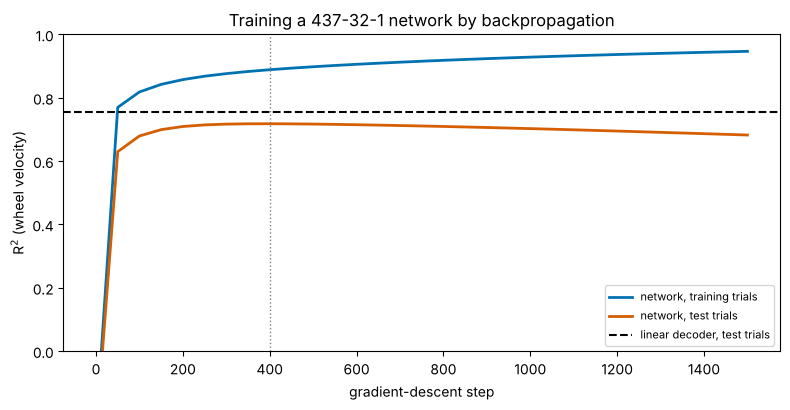

In [15]:
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(history[:, 0], history[:, 1], color=PALETTE[0], lw=2, label='network, training trials')
ax.plot(history[:, 0], history[:, 2], color=PALETTE[1], lw=2, label='network, test trials')
ax.axhline(r2_lin[0], color='black', ls='--', label='linear decoder, test trials')
ax.axvline(best[0], color='grey', ls=':', lw=1)
ax.set_ylim(0, 1); ax.set_xlabel('gradient-descent step'); ax.set_ylabel('R$^2$ (wheel velocity)')
ax.set_title(f'Training a {n_in}-32-1 network by backpropagation'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

The training error keeps falling, as gradient descent is designed to make it do. The **test** performance rises, peaks (about 0.72 at step 400), and then declines while the training performance keeps improving (0.95 by step 1500): the network has started to fit noise peculiar to the training trials (**overfitting**, Lesson 15). Even at its best, this small network does not beat the linear decoder (0.76). Neural networks are not automatically better; with this much data and this little nonlinearity in the problem, the linear map is hard to improve on (Exercise 7 tries a deeper network).

### Which neurons does the network use? Backpropagating to the inputs

`mlp_backward` also returns $\partial L/\partial\mathbf{X}$. With a different "loss", the decoded velocity $\hat v$ itself, the same backward pass gives $\partial \hat v/\partial x_j$: the **sensitivity** of the decoded velocity to each neuron's rate, separately for every time bin. In a linear decoder this sensitivity is just the weight, the same in every bin. In a network it depends on the operating point of every hidden unit (their $\tanh'$ slopes).

correlation of mean network sensitivity with the linear decoder's weights: 0.882
sensitivity while moving fast vs wheel still: correlation 0.992, overall size ratio 0.67
mean tanh slope of hidden units: moving fast 0.46, still 0.67


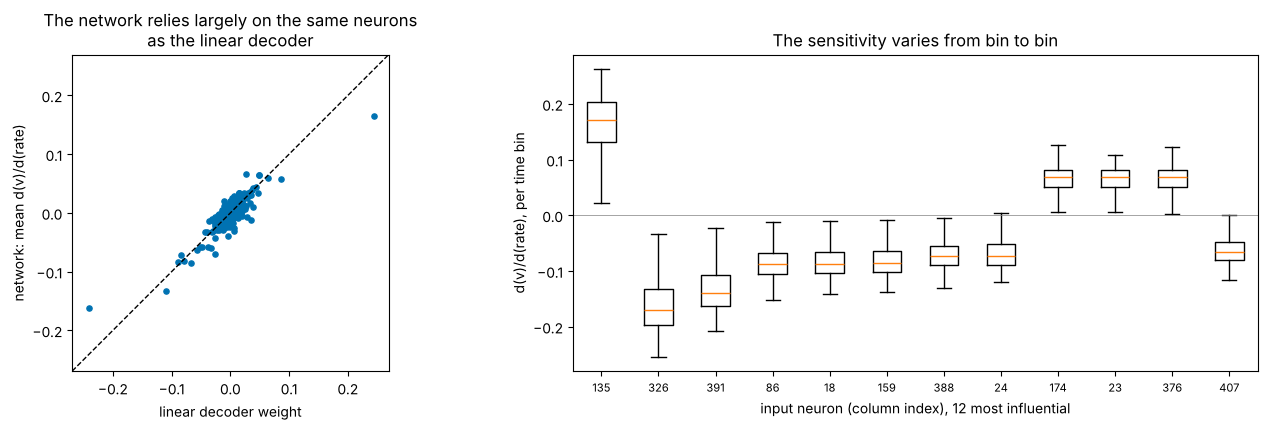

In [16]:
# Retrain to the best step (early stopping), then compute input sensitivities on the test trials.
rng_net = np.random.default_rng(0)
params_best = [(rng_net.normal(0, 1 / np.sqrt(n_in), (n_hid, n_in)), np.zeros(n_hid)),
               (rng_net.normal(0, 1 / np.sqrt(n_hid), (1, n_hid)), np.zeros(1))]
for step in range(int(best[0])):
    grads, _ = mlp_backward(params_best, mlp_forward(params_best, Xtr, acts_net), Ytr, acts_net)
    params_best = [(W - eta * gW, b - eta * gb) for (W, b), (gW, gb) in zip(params_best, grads)]

cache = mlp_forward(params_best, Xte, acts_net)
# "Loss" = sum over test bins of the decoded velocity: its backward pass gives d(v_hat)/dx for every bin.
dA = np.ones_like(cache[-1][1])
delta1 = (dA @ params_best[1][0]) * (1 - cache[1][1]**2)             # through the output weights and the tanh slopes
sens = delta1 @ params_best[0][0]                                    # shape (n_test, 437): d(v_hat)/d(neuron j) in each bin
mean_sens = sens.mean(axis=0)
speed_te = np.abs(Y_raw[~train, 0])
moving, still = speed_te > np.percentile(speed_te, 75), speed_te == 0
print(f"correlation of mean network sensitivity with the linear decoder's weights: {np.corrcoef(mean_sens, B_lin[1:, 0])[0, 1]:.3f}")
print(f"sensitivity while moving fast vs wheel still: correlation {np.corrcoef(sens[moving].mean(0), sens[still].mean(0))[0, 1]:.3f}, "
      f"overall size ratio {np.linalg.norm(sens[moving].mean(0)) / np.linalg.norm(sens[still].mean(0)):.2f}")
print(f"mean tanh slope of hidden units: moving fast {(1 - cache[1][1][moving]**2).mean():.2f}, still {(1 - cache[1][1][still]**2).mean():.2f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
axes[0].scatter(B_lin[1:, 0], mean_sens, s=14, color=PALETTE[0])
lim = 1.1 * np.abs(np.r_[B_lin[1:, 0], mean_sens]).max()
axes[0].plot([-lim, lim], [-lim, lim], 'k--', lw=1); axes[0].set_xlim(-lim, lim); axes[0].set_ylim(-lim, lim); axes[0].set_aspect('equal')
axes[0].set_xlabel('linear decoder weight'); axes[0].set_ylabel('network: mean d(v)/d(rate)')
axes[0].set_title('The network relies largely on the same neurons\nas the linear decoder')
order = np.argsort(-np.abs(mean_sens))[:12]
axes[1].boxplot([sens[:, j] for j in order], showfliers=False)
axes[1].set_xticks(np.arange(1, 13)); axes[1].set_xticklabels([str(j) for j in order], fontsize=8)
axes[1].axhline(0, color='grey', lw=0.5); axes[1].set_xlabel('input neuron (column index), 12 most influential')
axes[1].set_ylabel('d(v)/d(rate), per time bin'); axes[1].set_title('The sensitivity varies from bin to bin')
plt.tight_layout(); plt.show()

### Vanishing gradients on real inputs

Finally, the depth experiment of Part 4 with the real standardised rates as inputs: a 10-hidden-layer network of width 64, standard initialisation, gradient of the decoding loss for each layer.

sigmoid : gradient norm, first layer 1.6e-06, last layer 1.5e+00  (ratio 1.1e-06)
tanh    : gradient norm, first layer 5.2e-01, last layer 2.5e-01  (ratio 2.1e+00)
relu    : gradient norm, first layer 8.7e-01, last layer 3.3e+00  (ratio 2.7e-01)


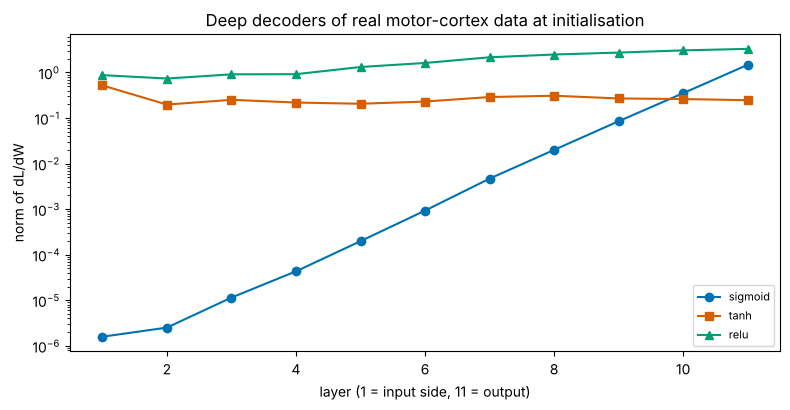

In [17]:
def deep_layer_norms(act, X_in, Y_in, depth=10, width=64, seed=1):
    rng = np.random.default_rng(seed)
    sizes = [X_in.shape[1]] + [width] * depth + [Y_in.shape[1]]
    gain = 2.0 if act == 'relu' else 1.0
    p = [(rng.normal(0, np.sqrt(gain / sizes[k]), (sizes[k + 1], sizes[k])), np.zeros(sizes[k + 1])) for k in range(depth + 1)]
    if act == 'sigmoid':
        A = [X_in]
        for W, b in p[:-1]:
            A.append(sigmoid(A[-1] @ W.T + b))
        P = A[-1] @ p[-1][0].T
        g = (P - Y_in) / len(Y_in); norms = [np.linalg.norm(g.T @ A[-1])]
        dA = g @ p[-1][0]
        for k in range(depth - 1, -1, -1):
            delta = dA * A[k + 1] * (1 - A[k + 1])
            norms.append(np.linalg.norm(delta.T @ A[k])); dA = delta @ p[k][0]
        return np.array(norms[::-1])
    acts_ = [act] * depth + ['linear']
    grads, _ = mlp_backward(p, mlp_forward(p, X_in, acts_), Y_in, acts_)
    return np.array([np.linalg.norm(gW) for gW, gb in grads])

fig, ax = plt.subplots(figsize=(8, 4.2))
for act, colour, mk in zip(['sigmoid', 'tanh', 'relu'], PALETTE, MARKERS):
    nrm = deep_layer_norms(act, Xtr[:2000], Ytr[:2000])
    ax.semilogy(np.arange(1, len(nrm) + 1), nrm, marker=mk, color=colour, label=act)
    print(f"{act:<8}: gradient norm, first layer {nrm[0]:.1e}, last layer {nrm[-1]:.1e}  (ratio {nrm[0] / nrm[-1]:.1e})")
ax.set_xlabel('layer (1 = input side, 11 = output)'); ax.set_ylabel('norm of dL/dW')
ax.set_title('Deep decoders of real motor-cortex data at initialisation'); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Interpretation.**
- **Backpropagation works on real data.** A hand-written backward pass, checked against central differences (relative error about $3\times10^{-7}$ on real data), trains a 437-32-1 network to decode wheel velocity.
- **The network does not win.** Its best test $R^2$ (0.72) falls short of the linear decoder's (0.76), and it begins to overfit after a few hundred steps.
- **Inside, it is largely linear.** Backpropagating to the inputs shows that, on average, it relies on much the same neurons, with the same signs, as the linear decoder (correlation about 0.88). Its sensitivities vary from bin to bin as hidden units move along their tanh curves. The average pattern is the same whether the wheel is turning fast or still (correlation 0.99), but it is about a third smaller during fast turns: the hidden units are more saturated then (mean tanh slope 0.46 against 0.67), so the network responds less to the same change in input.
- **Depth hurts sigmoids.** In a 10-layer sigmoid network on these inputs, the first layer's gradient is about a million times smaller than the last layer's, while tanh and ReLU with appropriate initialisation stay within a factor of a few.

**Limitations.** One architecture, one learning rate and plain gradient descent (Lessons 12 and 15 improve all three); a single train/test split by trials; the test trials were used to choose the stopping step, which is optimistic (a validation set should be used, Lesson 15); input sensitivities are local derivatives, which describe the response to small changes only.

# **Part 6: Where This Appears in Neuroscience and Machine Learning**

| Idea | Neuroscience | Machine learning |
|---|---|---|
| Chain rule | sensitivity of a rate to a synaptic weight through membrane potential and gain; parameter sensitivity of biophysical models | the derivative of a loss through any composition |
| Computation graph and reverse accumulation | fitting neural models with automatic differentiation (e.g. differentiable simulators) | backpropagation; automatic differentiation in PyTorch, JAX, TensorFlow |
| Affine-layer gradients ($\boldsymbol\delta\mathbf{a}^{\mathsf T}$) | Hebbian-like outer-product weight changes; the "credit assignment" problem in the brain | weight updates in every dense layer |
| Gradient checking | validating model-fitting code | testing custom layers and losses |
| Vanishing and exploding gradients | — | initialisation, ReLU, residual networks, normalisation, LSTMs |
| Input sensitivity | which neurons a decoder relies on; feature attribution in brain-computer interfaces | saliency maps; gradient-based attribution |

**Does the brain do backpropagation?** Exact backpropagation needs the backward pass to use the **transpose** of the forward weights (Part 3). Real synapses carry signals one way, so a separate feedback pathway would need its weights to match the forward ones: the "weight transport problem". Researchers study biologically plausible alternatives. Feedback alignment (Lillicrap et al., 2016) shows that **random** fixed feedback weights still let networks learn. Other proposals use dendritic error signals and predictive coding. How the brain solves credit assignment, deciding which synapses to change to improve behaviour, remains one of the central open questions of computational neuroscience.

# **Part 7: Summary and Lesson 11 Preview**

| Idea | Formula / code | What to remember |
|---|---|---|
| Chain rule | $\frac{dy}{dx} = f'(g(x))\,g'(x)$ | outer derivative at the inner value, times inner derivative; units cancel |
| Long chains | product of local derivatives | one flat link stalls the whole chain |
| Computation graph | nodes = operations, edges = values | forward pass stores values; backward pass multiplies local derivatives |
| Reverse accumulation | start with $\partial L/\partial L = 1$, go backwards | all parameter gradients for about the cost of one extra forward pass |
| Fan-out | sum the gradients along all paths | the `+=` in every backward rule |
| Affine layer | $\partial L/\partial\mathbf{W} = \boldsymbol\delta\mathbf{a}^{\mathsf T}$, $\partial L/\partial\mathbf{b} = \boldsymbol\delta$, $\partial L/\partial\mathbf{a} = \mathbf{W}^{\mathsf T}\boldsymbol\delta$ | outer products; weights run backwards as transposes |
| Activation | $\boldsymbol\delta_z = \boldsymbol\delta_a \odot \phi'(\mathbf{z})$ | elementwise; saturated units pass almost nothing |
| Gradient check | central differences on a small network | relative error $\lesssim 10^{-7}$ |
| Vanishing/exploding | product of $L$ factors | keep factors near 1: ReLU, Xavier/He initialisation, residuals |

**Lesson 11 — Critical points and curvature.** Gradients say which way is downhill. Where the gradient is zero, the bottom of a valley, a hilltop or a saddle, the **second derivative** (curvature) says which. Curvature also decides how fast learning can go, and why some directions in a loss landscape are flat and others sharp.